# 06d. Case study: the summer 2012 central U.S. heat wave: fixed-event-window verification

Metrics of every member on the observed window (all configurations are computed and saved; only `case.scored` are summarized). The start-resolved summary is the primary result; the pooled summary over starts is descriptive context (the starts are not independent cases).

## Metrics

*Event window, exact dates (primary):* event-mean absolute T error (K), event-mean anomaly (K), peak anomaly within the window (K) and its date error (days), exceedance days and longest run (days), accumulated exceedance (K day), mean area fraction above the gridpoint threshold (0-1), event-total precipitation (mm). *Timing-tolerant (secondary, window +-`peak_tolerance_days`):* peak anomaly and its date error, longest run. The peak is that of the anomaly series, searched by the same rules for observations and models.

*Ensemble, per start:* CRPS of the event-window mean and of the lead-window means (K); the event probability $p$, the member fraction with at least `min_event_days` consecutive hot days in the observed window (defined in advance), and its Brier score $(p - y)^2$, $y$ the observed outcome. With a single observed event the Brier score shows only how much probability went to what happened: it says nothing about reliability, discrimination or false alarms. No climatological skill reference is computed (a daily 90th percentile does not imply a 10 % probability of a 3-day event).

**The 06a-06h series** (summer 2012 central U.S. heat wave; each notebook reads the data it needs, computes, saves, then plots): `06a` observed event and simulation coverage; `06b` experiment QC; `06c` start-resolved regional trajectories; `06d` fixed-event-window metrics and maps; `06e` S2S lead-window scores; `06f` event probability; `06g` initialization contrasts; `06h` sensitivity of the event definition. Settings: `HeatwaveSettings` in `configs/hind_lead_eval_cases.py`; products: `util/heatwave_workflow.py`; methods: `util/heatwave_case.py`. Design, event definition and reference states: `06a`.

Every product is saved with the settings it was computed from and read back on the next run when those settings are unchanged; `FORCE_COMPUTE = True` recomputes this notebook's results, `FORCE_INPUTS = True` also re-reads the model output and observations. Model output is read only when a product has to be (re)computed.

## Outputs

`data/hind_lead_eval/heatwave_2012/`: `heat_metrics.csv` (members; shared by 06f-06g), `event_maps.nc`; figures `heatwave_metrics_by_start_<BIAS>.png`, `heatwave_metrics_<BIAS>.png`, `heatwave_maps_<BIAS>.png`.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options; plain values only, so `papermill -p` overrides work. Case definitions (experiments, regions, windows, options) are the settings defaults; change them for this notebook with `CASE_OVERRIDES`.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
LAND_SUPPORT_DIR = OBSERVATION_ROOT / "lnd_sea_mask"           # land fraction
AMIP_ROOT = OBSERVATION_ROOT / "E3SMv3"                        # free-running E3SMv3 DECK AMIP runs
WORKFLOW_NAME = "hind_lead_eval"

CONFIGS = {   # configuration key: raw case name (one case per start: INPUT_DATA_ROOT/<case name>_<YYYYMMDD>00/<ENxx>)
    "CLIM_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE",
    "HYB_BASE": "F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE",
    "DA_COUPLED": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED",
    "DA_ATM": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM",
    "DA_LND": "F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND",
}
# the experiments analysed are the keys of CONFIGS, in this order (tables and legends)

CASE_OVERRIDES = {}     # changes to the HeatwaveSettings defaults (configs/hind_lead_eval_cases.py), e.g. {"event_window": ("2012-06-27", "2012-07-07")}
FORCE_COMPUTE = False    # recompute this notebook's results even when they are saved with the same settings
FORCE_INPUTS = False     # also re-read the model output and observations (slow)


## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.fcst_init_experiment_config import STYLE_MAP, set_case_names
from configs.hind_lead_eval_cases import HeatwaveSettings, RunPaths
from util.hind_case_io import figure_saver, write_dataset, write_table
from util.heatwave_workflow import HeatwaveCase

paths = RunPaths(*(Path(p) for p in (INPUT_DATA_ROOT, WORK_DIR, DIAGNOSTIC_OUTPUT_ROOT, OBSERVATION_ROOT,
                                     LAND_SUPPORT_DIR, AMIP_ROOT)), workflow_name=WORKFLOW_NAME)
set_case_names(CONFIGS)   # the readers find each configuration's cases by these names
for c, name in CONFIGS.items():
    print(f"[CASE] {c}: {name}_<YYYYMMDD>00")
case = HeatwaveCase(HeatwaveSettings(paths=paths, **{"configs": tuple(CONFIGS), **CASE_OVERRIDES}), force_compute=FORCE_COMPUTE,
                   force_inputs=FORCE_INPUTS)
cfg = case.cfg


[CASE] CLIM_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_CLIM_BASE_<YYYYMMDD>00
[CASE] HYB_BASE: F20TR_ne30pg2_r05_IcoswISC30E3r5_HYB_BASE_<YYYYMMDD>00
[CASE] DA_COUPLED: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_COUPLED_<YYYYMMDD>00
[CASE] DA_ATM: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_ATM_<YYYYMMDD>00
[CASE] DA_LND: F20TR_ne30pg2_r05_IcoswISC30E3r5_DA_LND_<YYYYMMDD>00
[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012
[SCORED] ['CLIM_BASE', 'DA_COUPLED', 'DA_ATM']
[QC ONLY] ['HYB_BASE', 'DA_LND']


## 4. Read input

ERA5 daily-mean TREFHT and GPCP precipitation on the map box, both climatologies and the calendar-day thresholds (`observed_fields.nc`), and from them the observed events and the event window. Then the heat metrics of every member (`heat_metrics.csv`; computed from the member fields when missing).

In [4]:
obs = case.obs
print(f"[REGION] {cfg.region['name']}: {int(obs.mask.sum())} land points\n[CLIM] observed: {obs.clim_sources[0]}\n"
      f"[CLIM] model: {obs.clim_sources[1]}")
metrics = case.metrics

[READ] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/observed_fields.nc
[EVENT] window 2012-06-27 to 2012-07-07, observed peak 2012-07-04
[REGION] CENTRAL_US: 200 land points
[CLIM] observed: ERA5 1x1 daily: monthly means of the daily series
[CLIM] model: E3SMv3 AMIP monthly (v3.LR.amip_0101, v3.LR.amip_0151; cmip_ts (time bounds))
[STALE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/heat_metrics.csv: built with other settings, recomputing


[MODEL] CLIM_BASE TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] CLIM_BASE PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] HYB_BASE TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] HYB_BASE PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] DA_COUPLED TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] DA_COUPLED PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] DA_ATM TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] DA_ATM PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[MODEL] DA_LND TREFHT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}
[MODEL] DA_LND PRECT: {'init': 4, 'member': 20, 'lead': 61, 'lat': 27, 'lon': 61}


[SERIES] 20 (config, start) pairs, 40 anomaly series


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/heat_metrics.csv


## 5. Process and save

Member medians by start (primary) and pooled over starts (descriptive), for the scored configurations; the event-window TREFHT anomaly maps of each start and scored configuration (`event_maps.nc`).

In [5]:
from util.heatwave_workflow import PRIMARY_METRICS, TOLERANT_METRICS

scored = case.scored_metrics
cols = PRIMARY_METRICS + TOLERANT_METRICS
print("Member medians by start (primary):")
display(scored.groupby(["bias", "config", "init"])[cols].median().reindex(case.scored, level="config").round(2))
print("Pooled over starts (descriptive):")
display(scored.groupby(["bias", "config"])[cols].median().reindex(case.scored, level="config").round(2))
display(pd.DataFrame([obs.metrics], index=["OBS"])[cols].round(2))

event_maps = {}                     # ensemble-mean anomaly maps on the event window, per start
for b in cfg.biases:
    ref = obs.clim.clim_amip if b == "amip" else obs.clim.clim_obs
    per_start = [xr.concat([(case.on_calendar(case.field(c, "TREFHT"), i) - ref).sel(time=slice(*obs.window))
                            .mean(("time", "member")) for c in case.scored], pd.Index(case.scored, name="config"))
                 for i in case.inits]
    event_maps[b] = xr.concat(per_start, pd.Index(np.array(case.inits, dtype="datetime64[ns]"), name="init"))
maps_ds = xr.Dataset({f"model_anom_{b}": m for b, m in event_maps.items()})
maps_ds["obs_anom"] = (obs.T - obs.clim.clim_obs).sel(time=slice(*obs.window)).mean("time")
maps_ds.attrs.update(window=f"{obs.window[0]} to {obs.window[1]}", units="K")
write_dataset(maps_ds, case.data_dir / "event_maps.nc")

Member medians by start (primary):


event_mean_T_error  event_mean_anomaly  \
bias config     init                                                 
amip CLIM_BASE  2012-05-16               -4.45               -0.46   
                2012-05-21               -3.19                0.81   
                2012-05-26               -3.68                0.31   
                2012-05-31               -3.43                0.57   
     DA_COUPLED 2012-05-16               -3.24                0.76   
                2012-05-21               -1.91                2.08   
                2012-05-26               -3.79                0.21   
                2012-05-31               -2.96                1.04   
     DA_ATM     2012-05-16               -2.81                1.19   
                2012-05-21               -1.87                2.13   
                2012-05-26               -3.29                0.71   
                2012-05-31               -3.45                0.54   
none CLIM_BASE  2012-05-16               -4.45                0.87   
                2012-05-21               -3.19                2.13   
                2012-05-26               -3.68                1.64   
                2012-05-31               -3.43                1.90   
     DA_COUPLED 2012-05-16               -3.24                2.09   
                2012-05-21               -1.91                3.41   
                2012-05-26               -3.79                1.53   
                2012-05-31               -2.96                2.37   
     DA_ATM     2012-05-16               -2.81                2.52   
                2012-05-21               -1.87                3.46   
                2012-05-26               -3.29                2.04   
                2012-05-31               -3.45                1.87   

                            peak_anomaly  peak_date_error_days  \
bias config     init                                             
amip CLIM_BASE  2012-05-16          1.74                  -0.5   
                2012-05-21          2.94                  -3.0   
                2012-05-26          2.62                  -2.5   
                2012-05-31          2.71                   1.0   
     DA_COUPLED 2012-05-16          3.07                  -3.0   
                2012-05-21          4.13                   0.0   
                2012-05-26          2.32                  -2.0   
                2012-05-31          3.02                  -4.5   
     DA_ATM     2012-05-16          3.84                  -1.5   
                2012-05-21          4.43                  -4.0   
                2012-05-26          3.19                  -1.0   
                2012-05-31          3.38                  -2.5   
none CLIM_BASE  2012-05-16          3.27                   0.0   
                2012-05-21          4.27                  -2.5   
                2012-05-26          3.89                  -2.5   
                2012-05-31          4.08                   1.0   
     DA_COUPLED 2012-05-16          4.40                  -2.5   
                2012-05-21          5.58                   0.0   
                2012-05-26          3.68                  -1.5   
                2012-05-31          4.07                  -4.5   
     DA_ATM     2012-05-16          5.22                   0.0   
                2012-05-21          5.86                  -3.5   
                2012-05-26          4.77                  -1.0   
                2012-05-31          4.61                  -2.5   

                            exceedance_days  longest_run_days  \
bias config     init                                            
amip CLIM_BASE  2012-05-16              0.0               0.0   
                2012-05-21              1.0               1.0   
                2012-05-26              0.5               0.5   
                2012-05-31              0.5               0.5   
     DA_COUPLED 2012-05-16              1.0               1.0   
                2012-05-21         

Pooled over starts (descriptive):


event_mean_T_error  event_mean_anomaly  peak_anomaly  \
bias config                                                             
amip CLIM_BASE                -3.54                0.46          2.55   
     DA_COUPLED               -3.08                0.92          3.02   
     DA_ATM                   -3.06                0.94          3.67   
none CLIM_BASE                -3.54                1.78          3.92   
     DA_COUPLED               -3.08                2.24          4.11   
     DA_ATM                   -3.06                2.27          4.86   

                 peak_date_error_days  exceedance_days  longest_run_days  \
bias config                                                                
amip CLIM_BASE                   -2.0              0.0               0.0   
     DA_COUPLED                  -2.5              0.5               0.5   
     DA_ATM                      -2.0              2.0               2.0   
none CLIM_BASE                   -1.0              3.0               2.5   
     DA_COUPLED                  -1.5              4.0               3.0   
     DA_ATM                      -1.5              5.0               4.0   

                 accumulated_exceedance  area_fraction_mean  event_precip_mm  \
bias config                                                                    
amip CLIM_BASE                     0.00                0.09            35.82   
     DA_COUPLED                    0.02                0.12            35.97   
     DA_ATM                        1.44                0.16            33.52   
none CLIM_BASE                     2.40                0.22            35.82   
     DA_COUPLED                    2.95                0.26            35.97   
     DA_ATM                        4.89                0.31            33.52   

                 peak_anomaly_tol  peak_date_error_tol_days  \
bias config                                                   
amip CLIM_BASE               3.19                      -2.0   
     DA_COUPLED              4.18                      -3.5   
     DA_ATM                  4.65                      -6.0   
none CLIM_BASE               4.74                       1.0   
     DA_COUPLED              5.44                       0.0   
     DA_ATM                  5.99                      -2.5   

                 longest_run_tol_days  
bias config                            
amip CLIM_BASE                    1.0  
     DA_COUPLED                   3.0  
     DA_ATM                       4.0  
none CLIM_BASE                    5.0  
     DA_COUPLED                   6.0  
     DA_ATM                       7.0

,event_mean_T_error,event_mean_anomaly,peak_anomaly,peak_date_error_days,exceedance_days,longest_run_days,accumulated_exceedance,area_fraction_mean,event_precip_mm,peak_anomaly_tol,peak_date_error_tol_days,longest_run_tol_days
OBS,0.0,5.32,6.22,0,11,11,27.82,0.78,10.8,6.22,0,11


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_lead_eval/heatwave_2012/event_maps.nc


## 6. Plot and show

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_metrics_by_start_none.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_metrics_none.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_maps_none.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_metrics_by_start_amip.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_metrics_amip.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_lead_eval/heatwave_2012/heatwave_maps_amip.png


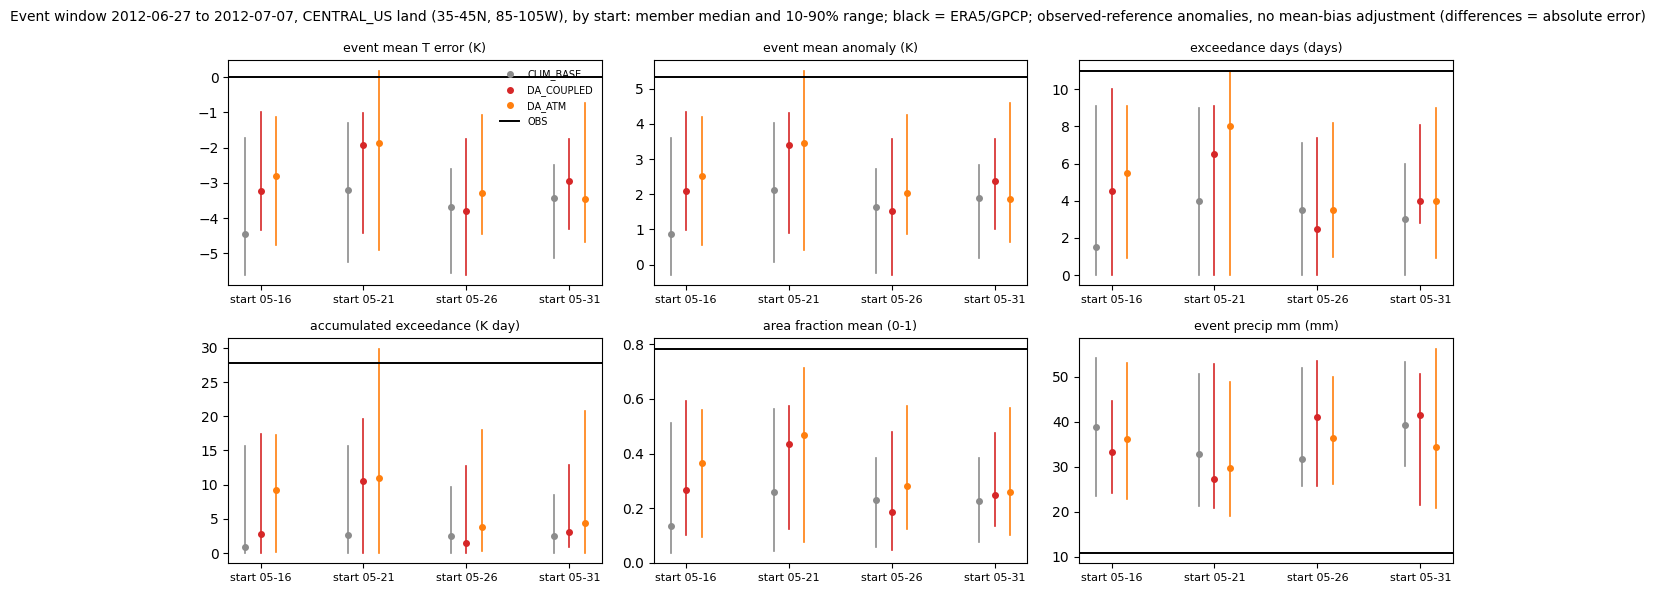

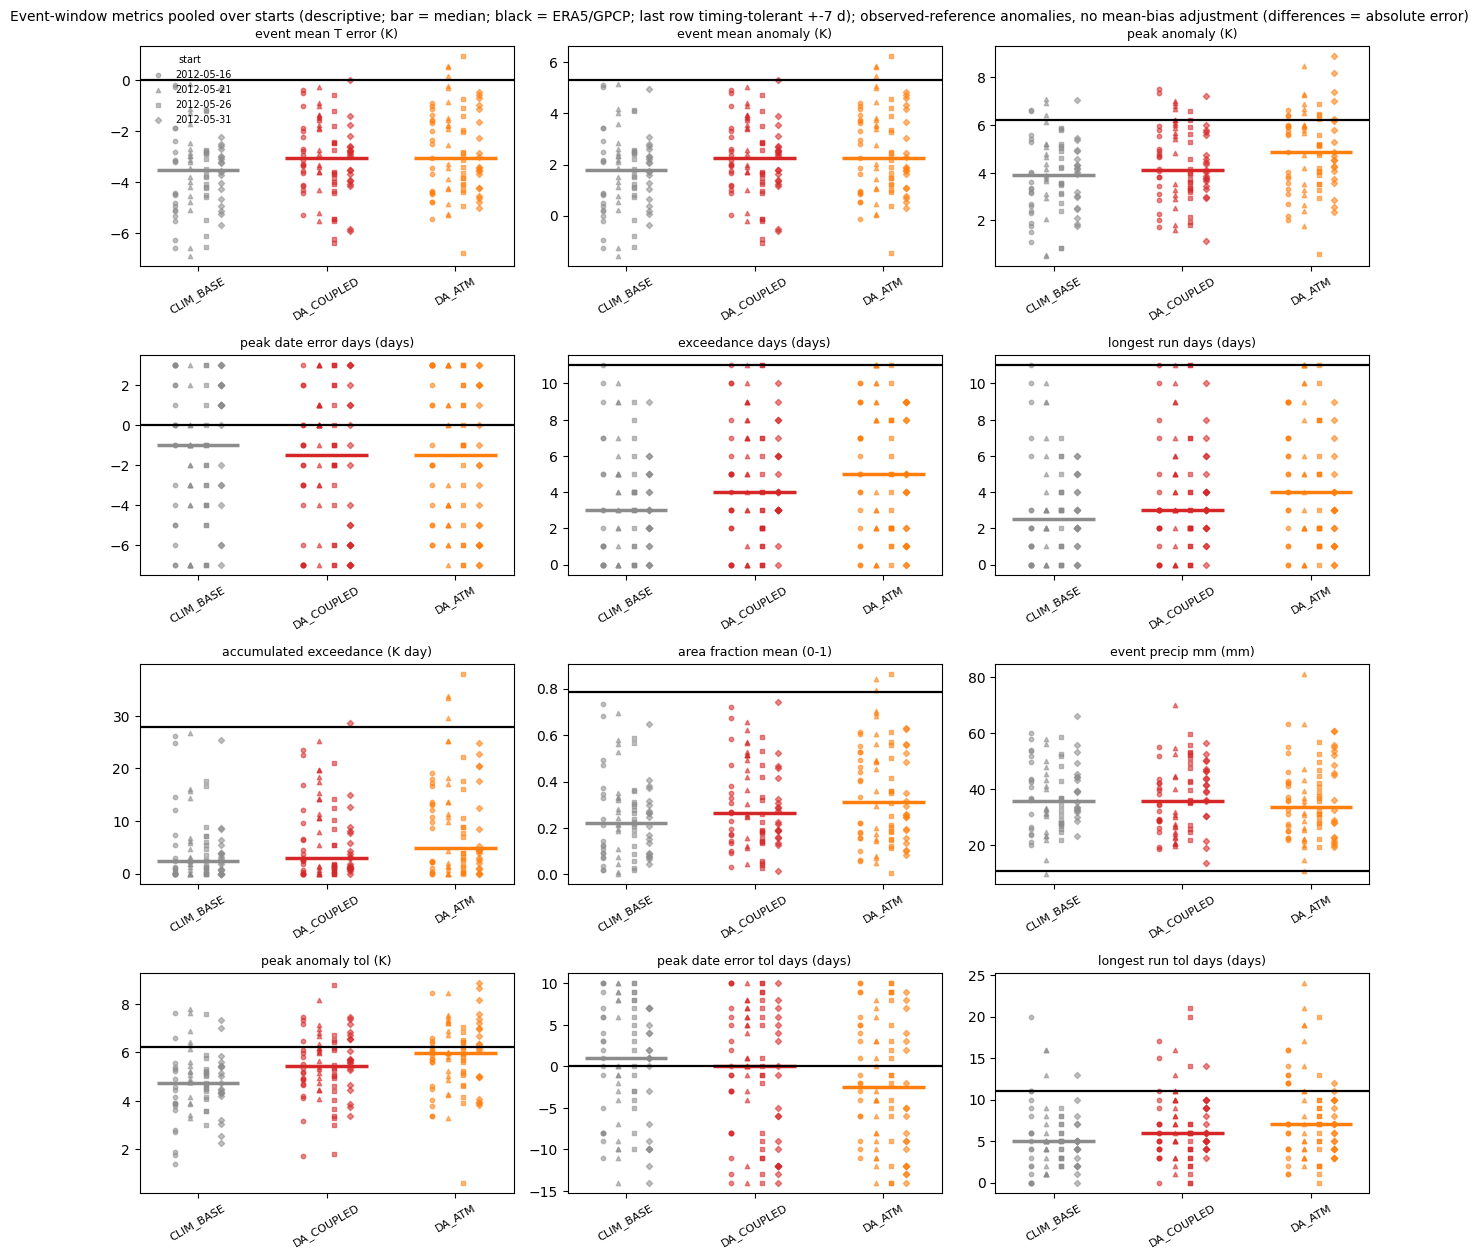

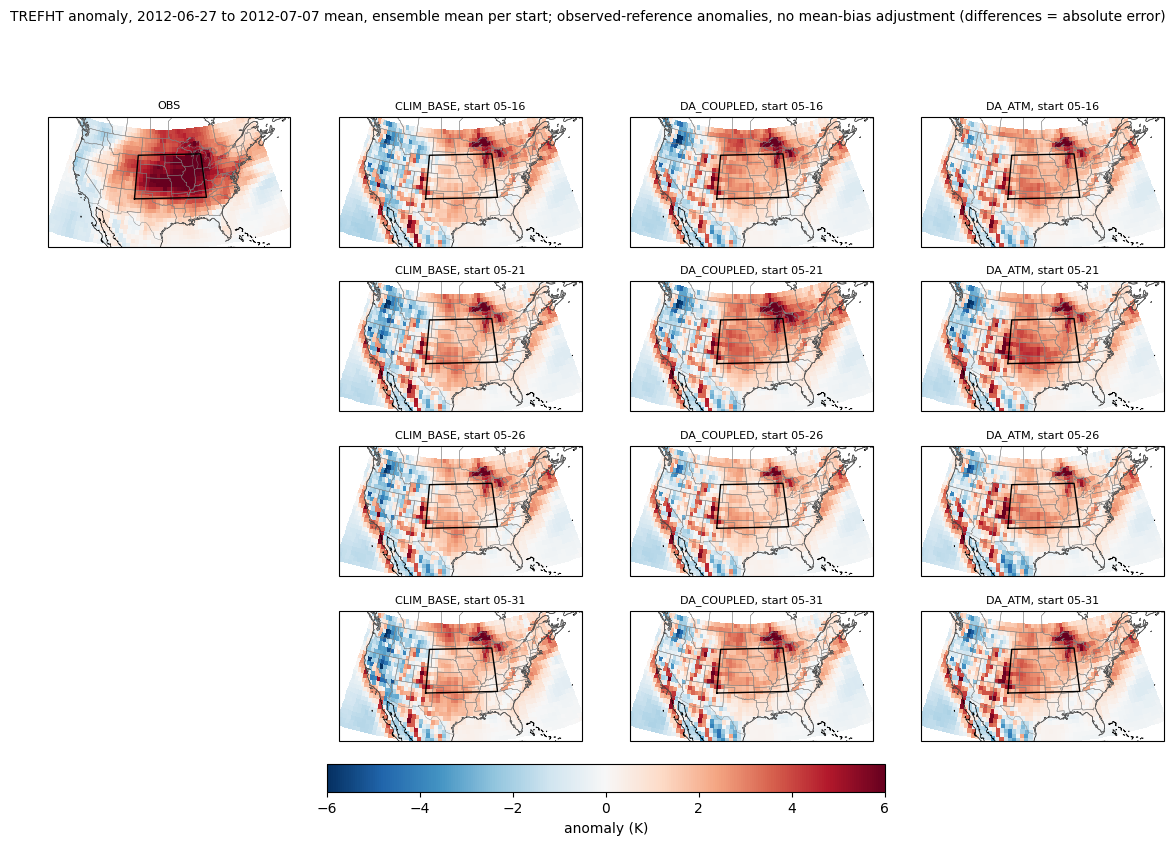

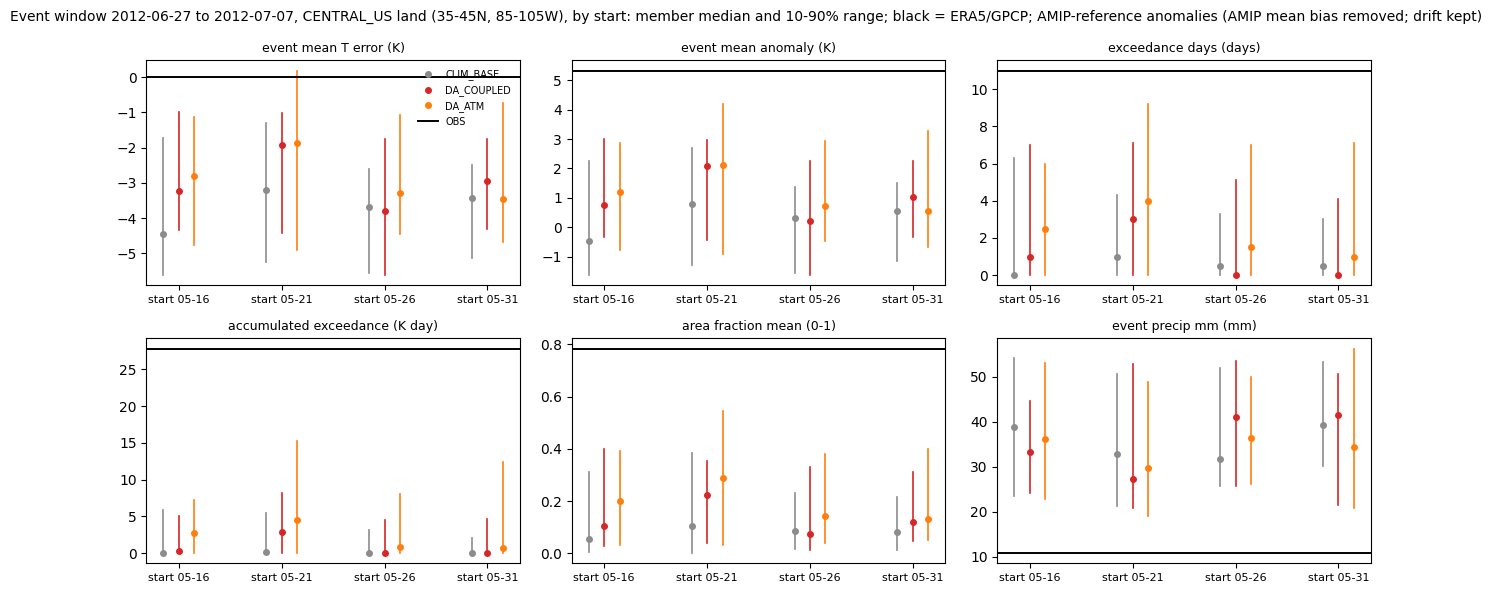

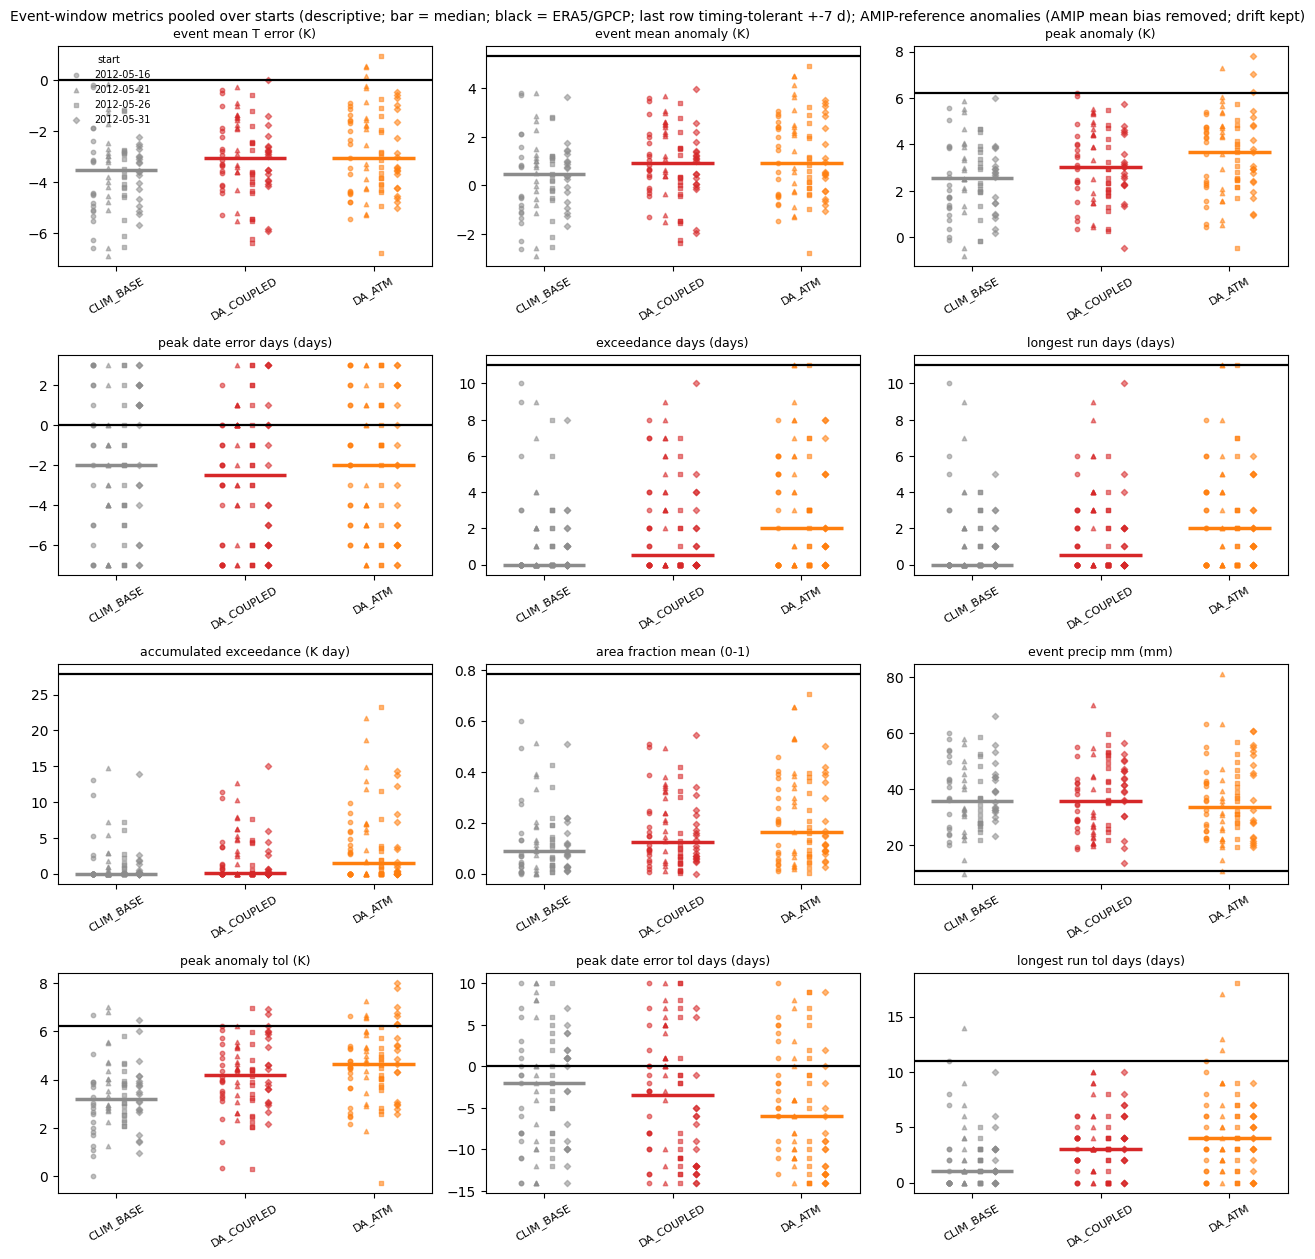

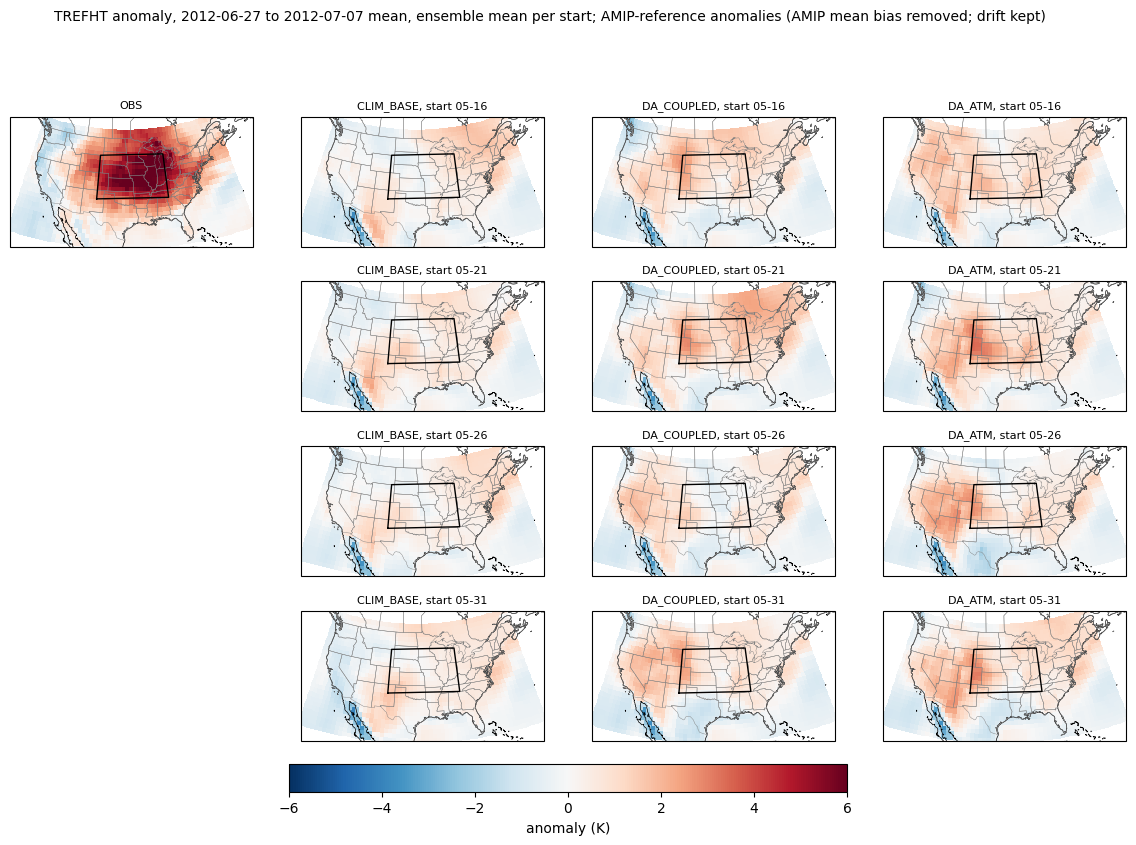

In [6]:
# ============================ Figure settings: edit here and rerun this cell ============================
SHOW = True          # False: save the figures without showing them
FIGURE_DPI = 200
FONT_SIZE = 18       # base font size (pt); every label of every figure scales with it
FONT_SCALES = dict(label=1.0, title=1.0, tick=0.9, legend=1.0, suptitle=1.15, cell=0.75)  # x FONT_SIZE

from util.fcst_init_plotting import set_font_size
set_font_size(FONT_SIZE, **FONT_SCALES)
save = figure_saver(case.figure_dir, dpi=FIGURE_DPI, show=SHOW)
# =========================================================================================================

from util.heatwave_case import plot_by_start, plot_maps_by_start, plot_metrics
from util.heatwave_workflow import METRIC_UNITS, REFERENCE_LABELS, START_METRICS

lo, hi = int(cfg.spread[0] * 100), int(cfg.spread[1] * 100)
for b in cfg.biases:
    mb = scored[scored.bias == b]
    save(plot_by_start(mb, obs.metrics, START_METRICS, case.scored, STYLE_MAP, units=METRIC_UNITS, spread=cfg.spread,
                       title=f"Event window {obs.window[0]} to {obs.window[1]}, {case.label}, by start: member median and "
                             f"{lo}-{hi}% range; black = ERA5/GPCP; {REFERENCE_LABELS[b]}"),
         f"heatwave_metrics_by_start_{b}.png")
    save(plot_metrics(mb, obs.metrics, cols, case.scored, STYLE_MAP, units=METRIC_UNITS,
                      title=f"Event-window metrics pooled over starts (descriptive; bar = median; black = ERA5/GPCP; "
                            f"last row timing-tolerant +-{cfg.peak_tolerance_days} d); {REFERENCE_LABELS[b]}"),
         f"heatwave_metrics_{b}.png")
    maps = {i: {c: maps_ds[f"model_anom_{b}"].sel(init=np.datetime64(i, "ns"), config=c, drop=True) for c in case.scored}
            for i in case.inits}
    save(plot_maps_by_start(maps_ds.obs_anom, maps, cfg.region,
                            title=f"TREFHT anomaly, {obs.window[0]} to {obs.window[1]} mean, ensemble mean per start; "
                                  f"{REFERENCE_LABELS[b]}"),
         f"heatwave_maps_{b}.png")